# Convolutional Neural Network
###### MNIST classification

Import dependencies

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
%matplotlib inline

load the mnist dataset

In [2]:
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.mnist.load_data()
x_train = (x_train_raw.reshape(-1, 28 * 28).astype(np.float32)) / 255.0
x_test = (x_test_raw.reshape(-1, 28 * 28).astype(np.float32)) / 255.0
y_train = np.eye(10, dtype=np.float32)[y_train_raw]
y_test = np.eye(10, dtype=np.float32)[y_test_raw]

x_val, y_val = x_train[55000:], y_train[55000:]
x_train, y_train = x_train[:55000], y_train[:55000]

### Neural Network

<br>Hyper-parameters

In [3]:
n_image_width = 28
n_image_height = 28
n_input_pixels = n_image_height * n_image_width
filter_width = 5
filter_height = 5
n_classes = 10  # digits 0-9
n_channels = 1  # black

con_1_features = 16
con_2_features = 32

learning_rate = 0.001

batch_size = 50

Layer Weights and biases

In [4]:
conv_lay_1 = {
    'weight': tf.Variable(
        tf.random.normal([filter_height, filter_width, n_channels, con_1_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([con_1_features], stddev=0.1))
}
conv_lay_2 = {
    'weight': tf.Variable(
        tf.random.normal([filter_height, filter_width, con_1_features, con_2_features], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([con_2_features], stddev=0.1))
}
fc_nn_lay_1 = {
    'weight': tf.Variable(
        tf.random.normal([7 * 7 * con_2_features, n_classes], stddev=0.1)),
    'bias': tf.Variable(tf.random.normal([n_classes], stddev=0.1))
}

trainable_variables = [
    conv_lay_1['weight'], conv_lay_1['bias'],
    conv_lay_2['weight'], conv_lay_2['bias'],
    fc_nn_lay_1['weight'], fc_nn_lay_1['bias']
]

#### Model

In [5]:
def model(X):
    # Resize image to proper shape
    x_img = tf.reshape(X, [-1, n_image_width, n_image_height,
                           n_channels])  # [batch, height, width, channels]

    h_conv_1 = tf.nn.conv2d(x_img, conv_lay_1['weight'], strides=[1, 1, 1, 1], padding='SAME')
    h_relu_1 = tf.nn.relu(h_conv_1 + conv_lay_1['bias'])
    op_pool_1 = tf.nn.max_pool(h_relu_1, ksize=[1, 2, 2, 1], strides=[1, 2, 2, 1], padding='SAME')

    h_conv_2 = tf.nn.conv2d(op_pool_1, conv_lay_2['weight'], strides=[1, 1, 1, 1], padding='SAME')
    h_relu_2 = tf.nn.relu(h_conv_2 + conv_lay_2['bias'])
    op_pool_2 = tf.nn.max_pool(h_relu_2, ksize=[1, 2, 2, 1], strides=[1, 2, 2, 1], padding='SAME')

    flat_lay_3 = tf.reshape(op_pool_2, [-1, 7 * 7 * con_2_features])

    h_nn_1 = tf.matmul(flat_lay_3, fc_nn_lay_1['weight']) + fc_nn_lay_1['bias']
    final_op = tf.nn.sigmoid(h_nn_1)
    return final_op

#### Error and Optimizer

In [6]:
# adam-optimizer
optimizer = tf.optimizers.Adam(learning_rate)

##### Prediction for test

In [7]:
def compute_accuracy(final_op, Y):
    correct_pred = tf.equal(tf.argmax(final_op, 1), tf.argmax(Y, 1))
    return tf.reduce_mean(tf.cast(correct_pred, tf.float32))

#### Start Training

In [8]:
@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        final_op = model(x)
        # mean-squared error
        error = tf.reduce_mean(0.5 * tf.square(final_op - y))
    grads = tape.gradient(error, trainable_variables)
    optimizer.apply_gradients(zip(grads, trainable_variables))
    return error


print("*********** Train ***********")

train_examples = len(x_train)

for i in range(train_examples // batch_size):
    x_batch = x_train[i * batch_size:(i + 1) * batch_size]
    y_batch = y_train[i * batch_size:(i + 1) * batch_size]
    err = train_step(x_batch, y_batch)

    if i % 100 == 0:
        val_x = x_val[:batch_size]
        val_y = y_val[:batch_size]
        acc = compute_accuracy(model(val_x), val_y)
        print("Batch: %d validation-error = %f accuracy = %f" %
              (i, err, acc * 100))

print("*********** Test ***********")

test_output = model(x_test)
acc = compute_accuracy(test_output, y_test)
print("Final Accuracy = %f" % (acc * 100))

*********** Train ***********
Batch: 0 validation-error = 0.183371 accuracy = 18.000000
Batch: 100 validation-error = 0.015940 accuracy = 88.000000
Batch: 200 validation-error = 0.009446 accuracy = 94.000000
Batch: 300 validation-error = 0.006182 accuracy = 92.000000
Batch: 400 validation-error = 0.007637 accuracy = 96.000000
Batch: 500 validation-error = 0.002804 accuracy = 96.000000
Batch: 600 validation-error = 0.005442 accuracy = 96.000000
Batch: 700 validation-error = 0.002279 accuracy = 96.000000
Batch: 800 validation-error = 0.002613 accuracy = 98.000000
Batch: 900 validation-error = 0.006405 accuracy = 98.000000
Batch: 1000 validation-error = 0.000999 accuracy = 98.000000
*********** Test ***********
Final Accuracy = 97.360001


#### Plot output

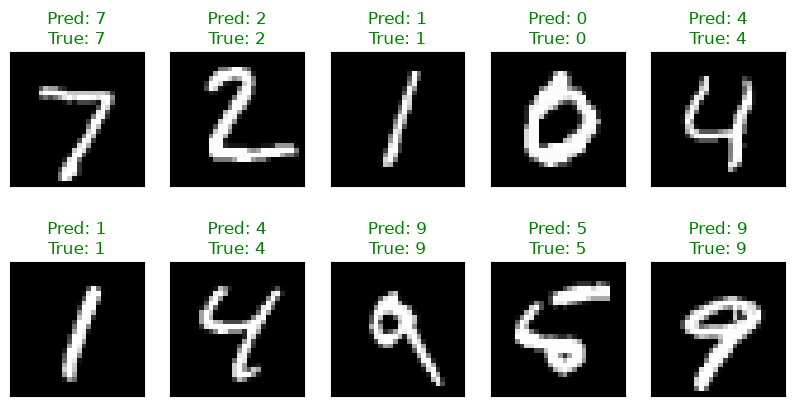

In [9]:
# function to plot the predictions
def plot_predictions(images, labels, predictions):
    fig = plt.figure(figsize=(10, 5))
    images = np.array(images).reshape(-1, 28, 28)
    for i in range(len(images)):
        ax = fig.add_subplot(2, 5, i + 1)
        ax.matshow(images[i], cmap="gray")
        plt.xticks([])
        plt.yticks([])
        ax.set_title("Pred: %d\nTrue: %d" % (predictions[i], labels[i]),
                     color=("green" if predictions[i] == labels[i] else "red"))


predictions = np.argmax(test_output[:10].numpy(), axis=1)

plot_predictions(x_test[:10], y_test_raw[:10], predictions)
plt.show()